# 📝 Foundations Quiz

This is a **hands-on, practical** quiz covering the Foundations notebooks (01–08). You'll write and run real code in the blank cells below, not just answer multiple choice. (For a quick conceptual self-check instead, see `quiz.md` in this folder.)

Answer each question in the provided cell. Some questions need code, others need a short written answer.

**Before you submit:**
1. **Restart & Run All** (notebook 02). Every cell must run top to bottom without errors. Run All stops at the first error, so a single broken cell hides every answer after it.
2. Upload this notebook **and** the `Quiz-OutputFiles` folder it creates.

## Setup
Run this first. Every file the quiz asks you to create goes into `OUT`.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path('Quiz-OutputFiles')
OUT.mkdir(exist_ok=True)

## Q1. Magic Commands (01)
Define three variables of different types. Then use a magic command to list them along with their types, and use a `!` shell command to capture the list of files in the current folder into a variable. Print how many files there are.

In [2]:
learner = 'Inuka Hulathduwage'
course_count = 3
hours = [15, 3, 2]
%whos
files = !dir /b /a-d
print('Number of files:', len(files))

Variable       Type           Data/Info
---------------------------------------
OUT            WindowsPath    Quiz-OutputFiles
Path           type           <class 'pathlib._local.Path'>
course_count   int            3
hours          list           n=3
json           module         <module 'json' from 'C:\\<...>\Lib\\json\\__init__.py'>
learner        str            Inuka Hulathduwage
np             module         <module 'numpy' from 'C:\<...>ges\\numpy\\__init__.py'>
pd             module         <module 'pandas' from 'C:<...>es\\pandas\\__init__.py'>
plt            module         <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>


Number of files: 9


In one sentence: what does `%whos` show that `%who` doesn't?

`%whos` includes each variable's type and a data/value summary, whereas `%who` lists names.

## Q2. Jupyter Workflow (02)
The three cells below only work if you run them out of order. **Reorder them** (don't change their code) so they run correctly from top to bottom.

In [3]:
price, quantity = 4.50, 3

In [4]:
total = price * quantity

In [5]:
print(f'Total cost: ${total:.2f}')

Total cost: $13.50


What do the execution-count numbers (like `[5]`) next to code cells tell you, and why can a notebook that works on your screen still fail for someone else?

Execution counts show the order in which code cells ran in the current kernel, not their position on the page. A notebook can depend on hidden variables or out-of-order execution that another person's fresh kernel does not have.

In Command mode, which keyboard shortcut **deletes** a cell, and which one inserts a new cell **above**?

In Command mode, press `D` twice to delete a cell and `A` to insert a cell above.

## Q3. Getting Help (03)
1. Use `?` to display the documentation for `round`. (Put any comment on its own line: `round?  # comment` is a `SyntaxError`.)
2. Using what the docs say about `round`'s second argument, round `3.14159` to 2 decimal places.

In [6]:
round?

In [7]:
print(round(3.14159, 2))

3.14


The code below raises an error. Run it, read the traceback from the bottom up, and then:
- In the Markdown cell after it, name the error type and explain what it means.
- In the code cell after that, fix it so it prints `Score: 5`.
- Finally, **comment out** the broken `print` line (select it and press `Ctrl+/`, or `Cmd+/` on Mac). Run All stops at the first error, so the error cell would otherwise keep your later answers from running.

In [8]:
score = 5
# print('Score: ' + score)  # Deliberate TypeError; commented for Run All.

`TypeError` means the operation is incompatible with the operand types: a string cannot be concatenated directly with an integer. Convert the score to text, or use an f-string. The broken line was commented programmatically; no keyboard shortcut action is claimed.

In [9]:
print(f'Score: {score}')

Score: 5


## Q4. Markdown (04)
Double-click the cell below and replace it with a Markdown cell containing:
- a heading `## My Hobbies`
- a bullet list of at least 3 hobbies
- a sentence containing a price, like *"my favorite hobby costs \$20 a month"*, that renders correctly (no accidental math!)
- the sample mean formula $\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$ written as **block** LaTeX

## My Hobbies

- Coding personal projects
- Watching movies
- Reading about space exploration

An illustrative hobby budget is \$20 per month; this is not a claim about my actual spending.

$$
\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
$$

## Q5. Files and Paths (05)
Use `pathlib` and `with open(..., encoding='utf-8')`:
1. Write `Hello World` to `OUT / 'hello.txt'`.
2. **Append** a second line, `Goodbye World`, without erasing the first.
3. Read the whole file back and print it.
4. Print the file's `.name`, `.suffix`, and whether it `.exists()`.

In [10]:
hello = OUT / 'hello.txt'
with open(hello, 'w', encoding='utf-8') as f:
    f.write('Hello World\n')
with open(hello, 'a', encoding='utf-8') as f:
    f.write('Goodbye World\n')
with open(hello, encoding='utf-8') as f:
    print(f.read())
print(hello.name, hello.suffix, hello.exists())

Hello World
Goodbye World

hello.txt .txt True


## Q6. JSON (05)
Create a dictionary describing a course (name, number of credits, and a **list** of topics). Save it to `OUT / 'course.json'` with `indent=2`, read it back into a new variable, and print whether the two dictionaries are equal (`==`).

In [11]:
# Illustrative course structure, not a verified catalog credit count.
course = {'name': 'Data Science', 'credits': 3,
          'topics': ['Python', 'Data analysis', 'Visualization']}
with open(OUT / 'course.json', 'w', encoding='utf-8') as f:
    json.dump(course, f, indent=2)
with open(OUT / 'course.json', encoding='utf-8') as f:
    course_back = json.load(f)
print('Equal:', course == course_back)
assert course == course_back

Equal: True


## Q7. Data I/O with Pandas (06)
1. Create a small DataFrame (3–5 rows, your own data, at least one number column) and save it to `OUT / 'my_data.csv'` **without** the index.
2. Read it back with Pandas, and show the first rows with `.head()` and the summary statistics with `.describe()`.
3. Convert it to JSON at `OUT / 'my_data.json'` using `orient='records'`, and print the file's text.

In [12]:
# Personal hobby data supplied by Inuka.
my_df = pd.DataFrame({'hobby': ['Coding personal projects', 'Watching movies',
                              'Reading about space exploration'],
                      'hours_per_week': [15, 3, 2]})
my_df.to_csv(OUT / 'my_data.csv', index=False)
my_back = pd.read_csv(OUT / 'my_data.csv')
display(my_back.head())
display(my_back.describe())
my_back.to_json(OUT / 'my_data.json', orient='records', indent=2)
print((OUT / 'my_data.json').read_text(encoding='utf-8'))
assert my_df.equals(my_back)

,hobby,hours_per_week
0,Coding personal projects,15
1,Watching movies,3
2,Reading about space exploration,2


,hours_per_week
count,3.000000
mean,6.666667
std,7.234178
min,2.000000
25%,2.500000
50%,3.000000
75%,9.000000
max,15.000000


[
  {
    "hobby":"Coding personal projects",
    "hours_per_week":15
  },
  {
    "hobby":"Watching movies",
    "hours_per_week":3
  },
  {
    "hobby":"Reading about space exploration",
    "hours_per_week":2
  }
]


## Q8. Plotting (07)
Create a line plot of $y = x^2$ for 50 evenly spaced $x$ values from 0 to 10 (use NumPy). Give it a title and axis labels, and save it to `OUT / 'squares.png'` **before** you show it.

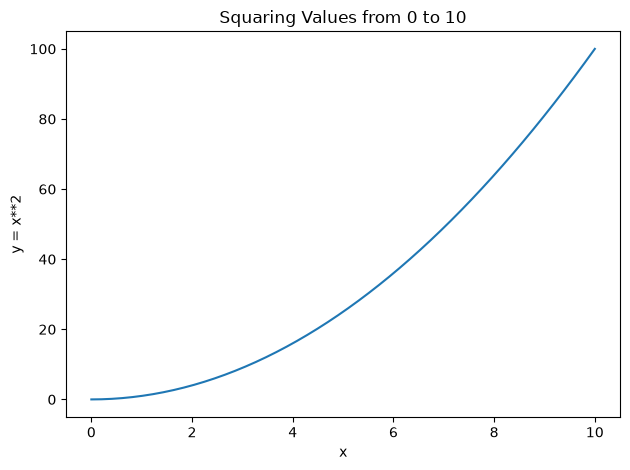

In [13]:
x = np.linspace(0, 10, 50)
fig, ax = plt.subplots()
ax.plot(x, x**2)
ax.set(title='Squaring Values from 0 to 10', xlabel='x', ylabel='y = x**2')
fig.tight_layout()
fig.savefig(OUT / 'squares.png', dpi=150, bbox_inches='tight')
plt.show()

## Q9. Choosing and Building a Chart (07)
Generate 200 exam scores with `np.random.seed(1)` and `np.random.normal(70, 12, size=200)`. Pick the **best chart** for showing their distribution, and draw it with a title, axis labels, and a dashed vertical line marking the mean (with a legend).

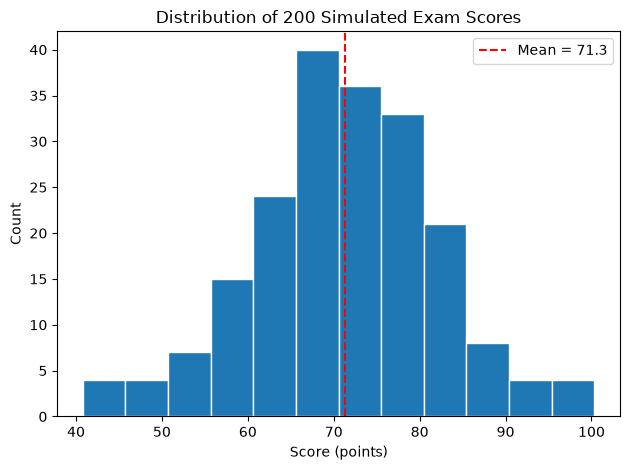

In [14]:
np.random.seed(1)
exam_scores = np.random.normal(70, 12, size=200)
fig, ax = plt.subplots()
ax.hist(exam_scores, bins=12, edgecolor='white')
ax.axvline(exam_scores.mean(), linestyle='--', color='red', label=f'Mean = {exam_scores.mean():.1f}')
ax.set(title='Distribution of 200 Simulated Exam Scores', xlabel='Score (points)', ylabel='Count')
ax.legend()
fig.tight_layout()
plt.show()

In one or two sentences: why did you choose that chart type over a bar chart or a line plot?

A histogram groups numeric scores into intervals to show the distribution's shape and spread. A bar chart compares categories, while a line plot implies an ordered sequence between observations.

## Q10. Timing (08)
Compare squaring one million numbers with a Python loop (or list comprehension) over a **list** and with NumPy on an **array**:
1. Create both inputs **before** timing, so the setup isn't measured.
2. Confirm that both approaches produce the same values.
3. Use `%timeit -o` for each, and print how many times faster NumPy is.

In [15]:
number_list = list(range(1_000_000))
number_array = np.arange(1_000_000)
assert np.array_equal([v**2 for v in number_list], number_array**2)
list_time = %timeit -o -n 3 -r 3 [v**2 for v in number_list]
numpy_time = %timeit -o -n 3 -r 3 number_array**2
print(f'NumPy is {list_time.average/numpy_time.average:.2f} times as fast in this run')

93.3 ms ± 3.6 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)
2.05 ms ± 177 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)
NumPy is 45.50 times as fast in this run


## Q11. Reflection
In 2–3 sentences each:
1. Why is it useful to mix Markdown and code in Jupyter notebooks?
2. Why should you Restart & Run All before submitting this quiz?

1. Markdown supplies context, questions, assumptions, and interpretations alongside executable calculations. Keeping narrative beside results helps a reader follow and reproduce an analysis.
2. Restart & Run All checks the saved cell order with an empty kernel. It exposes missing setup and stale-state dependencies before submission, making the notebook reproducible for the grader.

## 📦 Check Your Output Files
Run this last. You should see `hello.txt`, `course.json`, `my_data.csv`, `my_data.json`, and `squares.png`. Upload the `Quiz-OutputFiles` folder along with this notebook.

In [16]:
for path in sorted(OUT.rglob('*')):
    print(path)

Quiz-OutputFiles\course.json
Quiz-OutputFiles\hello.txt
Quiz-OutputFiles\my_data.csv
Quiz-OutputFiles\my_data.json
Quiz-OutputFiles\squares.png
